In [605]:
import pandas as pd # Importing the pandas librabry
df = pd.read_csv('./finanical_report_2018.csv', na_values = ["n/a"])
df.info()
                 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3845 entries, 0 to 3844
Data columns (total 13 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Stock Code                           3845 non-null   int64  
 1   Market Value of Equity               3845 non-null   float64
 2   Total Market Value                   3845 non-null   float64
 3   Stock Return                         3817 non-null   float64
 4   Total Investment Expenditure         3845 non-null   float64
 5   Amortization and Depreciation        3845 non-null   float64
 6   Book Value                           3845 non-null   float64
 7   Operating Income after Depreciation  3845 non-null   float64
 8   Annual Dividends                     3845 non-null   float64
 9   Leverage                             3845 non-null   float64
 10  Cash                                 3845 non-null   float64
 11  Age                           

In [607]:
df["Size"] = pd.to_numeric(df["Size"], errors = 'coerce') # We see that the data type for 'Size' is 'Object', meaning that it probarbly has a non_numeric value , thus we must convert all values to a numeric value, so we can check for any dirty data
print(df.dtypes)

Stock Code                               int64
Market Value of Equity                 float64
Total Market Value                     float64
Stock Return                           float64
Total Investment Expenditure           float64
Amortization and Depreciation          float64
Book Value                             float64
Operating Income after Depreciation    float64
Annual Dividends                       float64
Leverage                               float64
Cash                                   float64
Age                                    float64
Size                                   float64
dtype: object


In [609]:
null_masks = df.isnull().sum() # Returns a mask list showing any null values in any of the coloumns
null_masks

Stock Code                              0
Market Value of Equity                  0
Total Market Value                      0
Stock Return                           28
Total Investment Expenditure            0
Amortization and Depreciation           0
Book Value                              0
Operating Income after Depreciation     0
Annual Dividends                        0
Leverage                                0
Cash                                    0
Age                                     0
Size                                    1
dtype: int64

In [611]:
x = 0
for stock_code in df.index:
    for feature in df.columns:
        
        if pd.isna(df.at[stock_code, feature]) == True:
            print(f"Stock Code: {stock_code}, feature: {feature} ")
            x = x + 1
print(f"Total missing values= {x} ")
#1.A

Stock Code: 316, feature: Stock Return 
Stock Code: 779, feature: Stock Return 
Stock Code: 781, feature: Stock Return 
Stock Code: 1124, feature: Size 
Stock Code: 1749, feature: Stock Return 
Stock Code: 1903, feature: Stock Return 
Stock Code: 2059, feature: Stock Return 
Stock Code: 2681, feature: Stock Return 
Stock Code: 2701, feature: Stock Return 
Stock Code: 2767, feature: Stock Return 
Stock Code: 2792, feature: Stock Return 
Stock Code: 3024, feature: Stock Return 
Stock Code: 3071, feature: Stock Return 
Stock Code: 3098, feature: Stock Return 
Stock Code: 3155, feature: Stock Return 
Stock Code: 3162, feature: Stock Return 
Stock Code: 3195, feature: Stock Return 
Stock Code: 3199, feature: Stock Return 
Stock Code: 3293, feature: Stock Return 
Stock Code: 3297, feature: Stock Return 
Stock Code: 3308, feature: Stock Return 
Stock Code: 3312, feature: Stock Return 
Stock Code: 3316, feature: Stock Return 
Stock Code: 3509, feature: Stock Return 
Stock Code: 3604, feature: 

#1.B
To identify missing or wrong values, we used a method of seraching for any 'N/A / NaN ' values when loading the data. Additonally, when looking at the data types, we see that the data type for 'Size' is object, meaning there could possibly be wrong values in this column as you would expect 'float64' like the other columns. After converting all values to a numeric form within the 'Size' column, we then were able to calaculate the the total number of 'Null' values within the dataset as well as which column ( feature) the null values belong to, by making use of the 'sum feature' and ' isnull' feature. Finally, to know which 'Null value' belonged to which 'Stock code', we used a combination of 'for loops' and ' if statements' to print out the corrseponding null value to the 'stoc code' of which it belongs.

In [614]:
for stock_code in df.index:
    for feature in df.columns:
        
        if pd.isna(df.at[stock_code, feature]) == True:
            df.at[stock_code, feature] = df[feature].median()
df.to_csv('Cleaned_dataset')

To replace the null values in each of the columns for "Stock Return" and "Size", I decided to use the median value in each respective colummn to replace the missing values in that column. I chose the median value as it has a robustness to outliers. The median value is likely to be less affected by extreme values which could give a wrong representation/image of that column as a whole. The median is also a simple statistic to calculate and interpret, thus making it easier to understand as well also increasing the computational efficiency to handle large datasets. Furthermore, as the median is the middle value, this may help preserve the distribution of the data within that column, thus making the data appear more accurate/ better presentation. I did this, by first identifying the null values in each column using a for loop and then preceeding to replace that 'null value' with the median value of that column/feature. I then loaded the 'Clean data' to a csv file

In [617]:
# Part 2 Calculating two new feature values for each company: (V/P, Investment_2018) using the 
# following equations: 
# V/P = ((1-1.24*0.12)*Book_Value +1.24*1.12* Operating_Income_after_Depreciation - 
# 1.24*0.12* Annual_Dividends)/ Market_Value_of_Equity 

# I𝒏𝒗𝒆𝒔𝒕𝒎𝒆𝒏𝒕𝟐𝟎𝟏𝟖 = 𝑇𝑜𝑡𝑎𝑙 𝐼𝑛𝑣𝑒𝑠𝑡𝑚𝑒𝑛𝑡 𝐸𝑥𝑝𝑒𝑛𝑑𝑖𝑡𝑢𝑟𝑒 − 𝐴𝑚𝑜𝑟𝑡𝑖𝑧𝑎𝑡𝑖𝑜𝑛 𝑎𝑛𝑑 𝐷𝑒𝑝𝑟𝑒𝑐𝑖𝑎𝑡𝑖𝑜n

In [619]:
df["V/P"] = ((1-1.24*0.12)*df["Book Value"] +1.24*1.12* df["Operating Income after Depreciation"] - 1.24*0.12* df["Annual Dividends"])/ df["Market Value of Equity"]
print(df["V/P"])

0       0.357077
1       0.528143
2       0.597518
3       0.482893
4       0.481323
          ...   
3840    0.333897
3841    0.363928
3842    0.619805
3843    0.258821
3844    0.277867
Name: V/P, Length: 3845, dtype: float64


In [621]:
df["Investment 2018"]= df["Total Investment Expenditure"] - df["Amortization and Depreciation"]
print(df["Investment 2018"])

0          207.321400
1          662.503500
2          801.191621
3        10224.290050
4          276.220800
            ...      
3840     26398.821590
3841     64287.128500
3842     25310.405780
3843    209871.307800
3844      9538.654090
Name: Investment 2018, Length: 3845, dtype: float64


In [623]:
df.to_csv('Cleaned_dataset.csv')

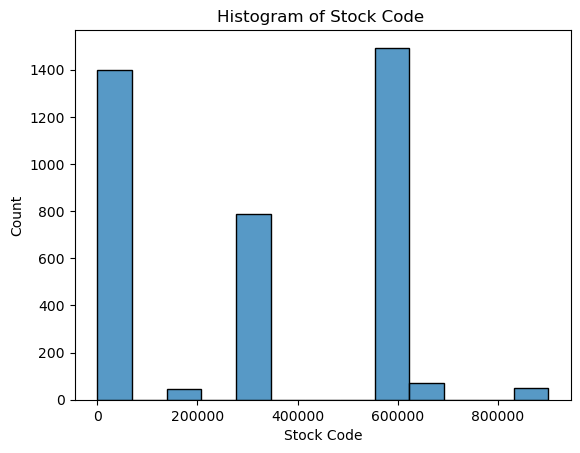

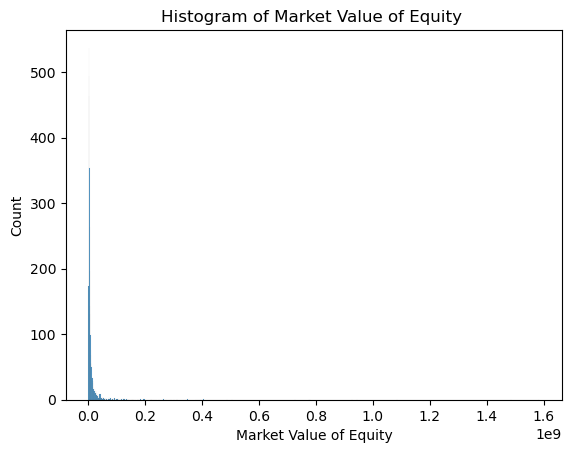

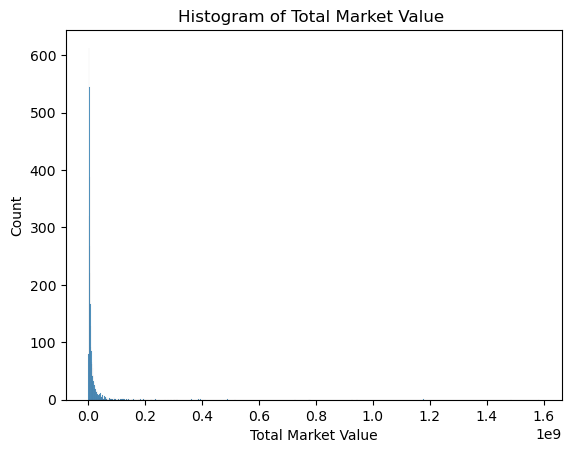

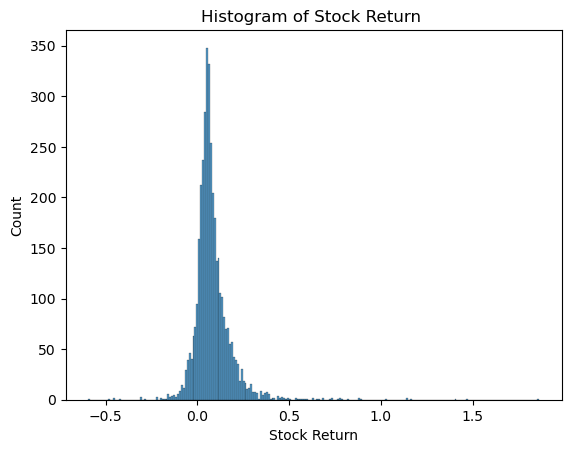

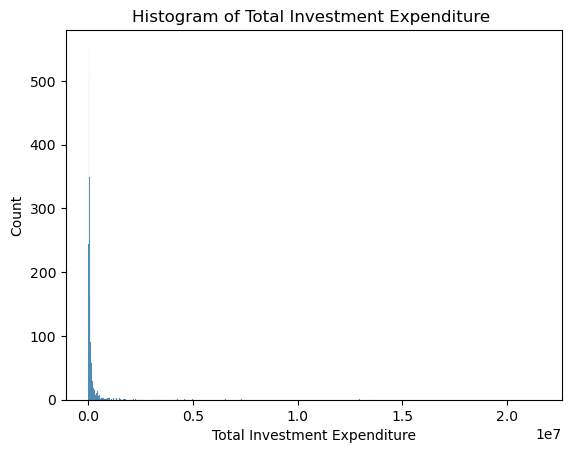

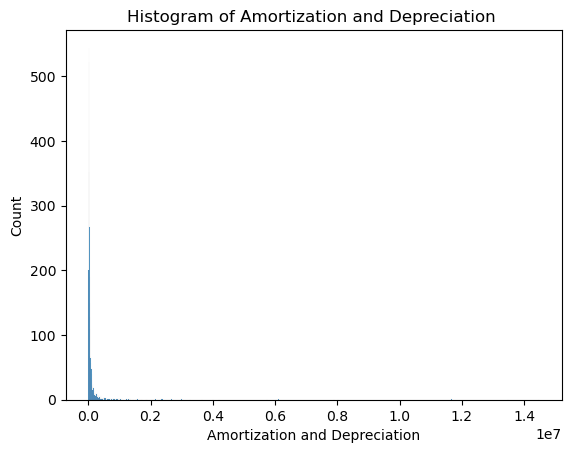

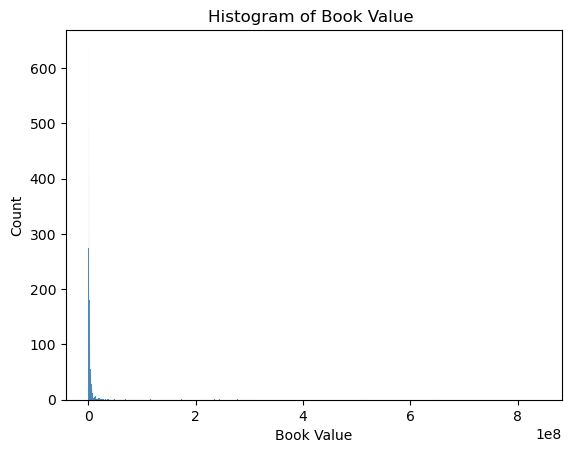

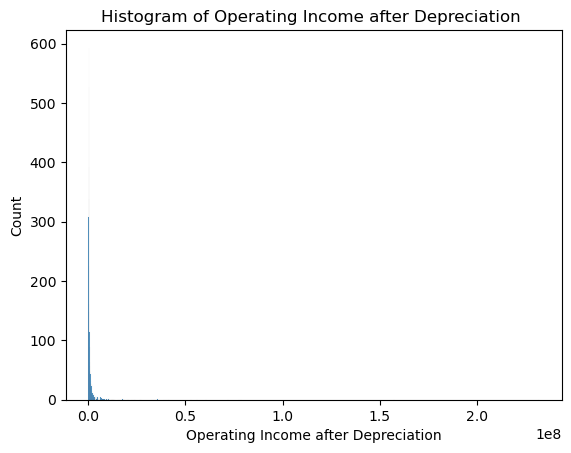

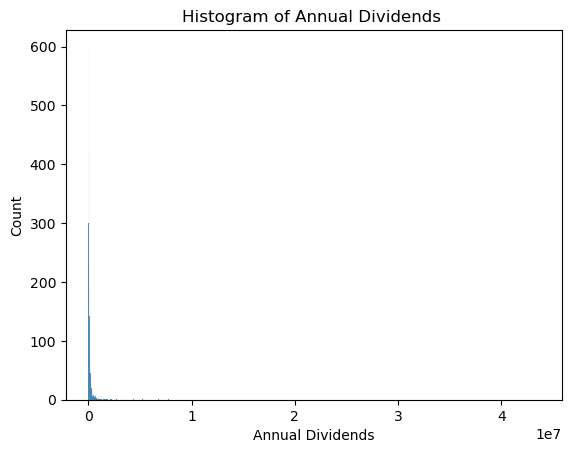

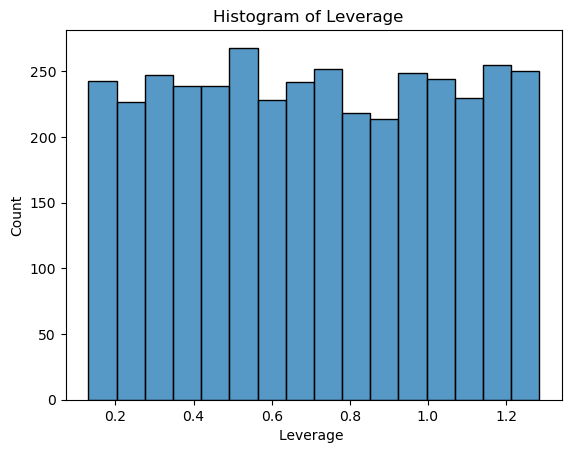

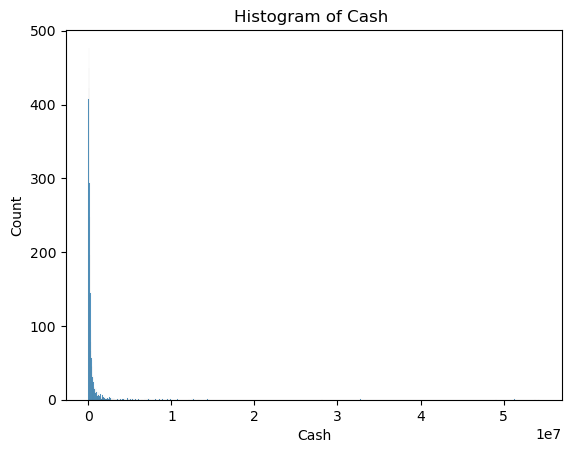

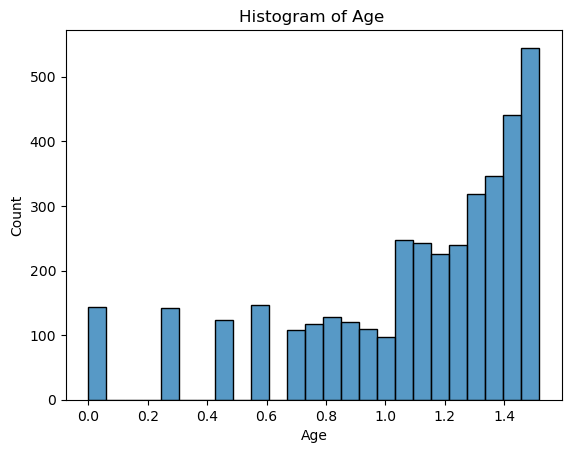

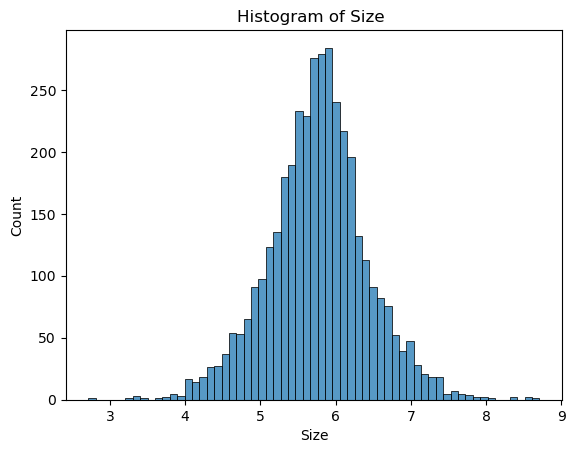

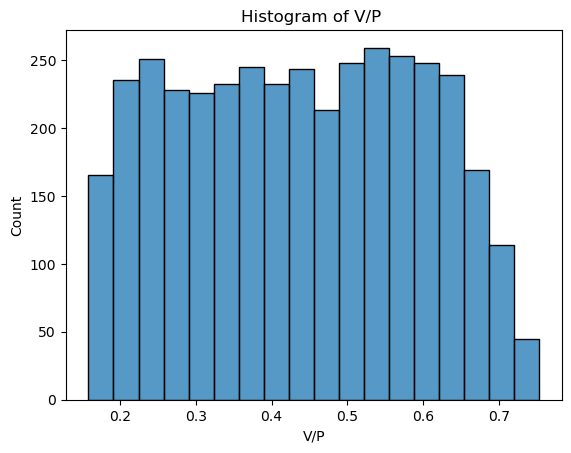

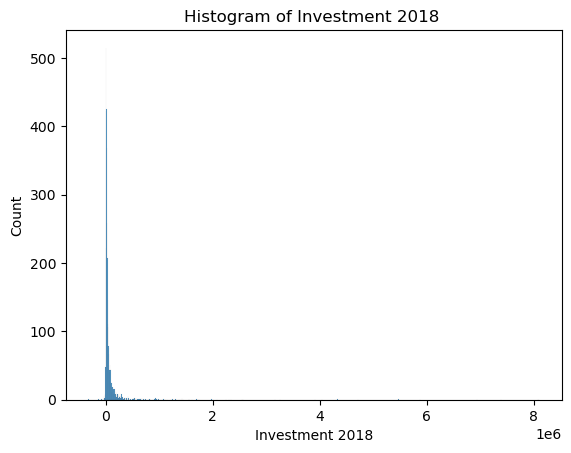

In [625]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in df.columns:
    sns.histplot(df[feature])
    plt.title(f'Histogram of {feature} ' )
    plt.show()

In [626]:
# Part 2 - Question A
# Normalizing the data
import numpy as np
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler


df["Size"] = (df["Size"] - np.min(df["Size"]))/(np.max(df["Size"])-np.min(df["Size"])) # Using the min/max normalization method as the feature graph 'Size' appeared to have a uniform distribution.
df["Leverage "] = (df["Leverage "] - np.min(df["Leverage "]))/(np.max(df["Leverage "])-np.min(df["Leverage "]))
df["V/P"] = (df["V/P"] - np.min(df["V/P"]))/(np.max(df["V/P"])-np.min(df["V/P"]))

df['Age'] = np.sqrt(df['Age']) # The data for 'Age' and 'Market VValue of Equity was slightly skewed to the right, and contained '0' values, thus making the square-root normalization, a useful tool as it can hald values that are 0


pt = PowerTransformer(method='yeo-johnson')
df['Investment 2018'] = pt.fit_transform(df[['Investment 2018']]) # The Yeo-Johnson normalization method can help reduce skewness within models and handle both negative and positive values


# I have chosen to use the Logarithmic normalization method for these graphs as they are slightly skewed and contain significant outliers, also while not having values that are negative or equal to 0, thus making Logarithmc normalization possible
df['Market Value of Equity'] = np.log(df['Market Value of Equity'])
df['Total Market Value'] = np.log(df['Total Market Value'])
df['Cash'] = np.log(df['Cash'])
df['Annual Dividends'] = np.log(df['Annual Dividends'])
df['Total Investment Expenditure'] = np.log(df['Total Investment Expenditure'])
df['Amortization and Depreciation'] = np.log(df['Amortization and Depreciation'])
df['Book Value'] = np.log(df['Book Value'])
df['Operating Income after Depreciation'] = np.log(df['Operating Income after Depreciation'])

scaler = StandardScaler()
df['Stock Return'] = scaler.fit_transform(df[['Stock Return']])


df.to_csv('Cleaned_dataset.csv')

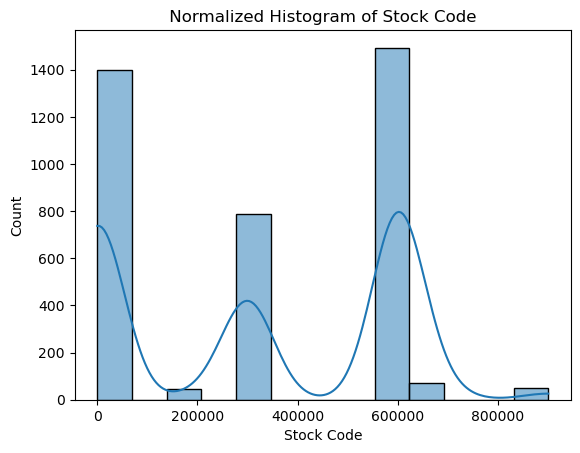

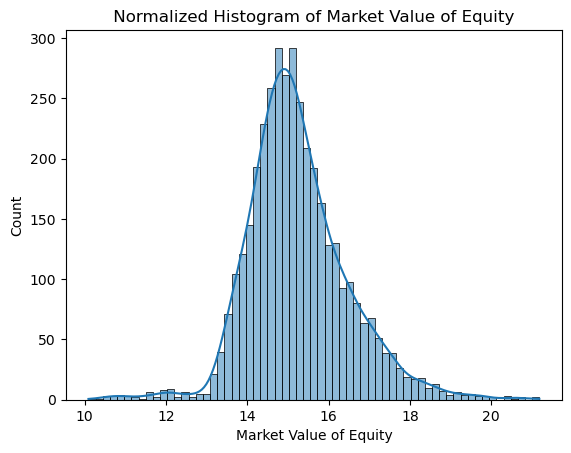

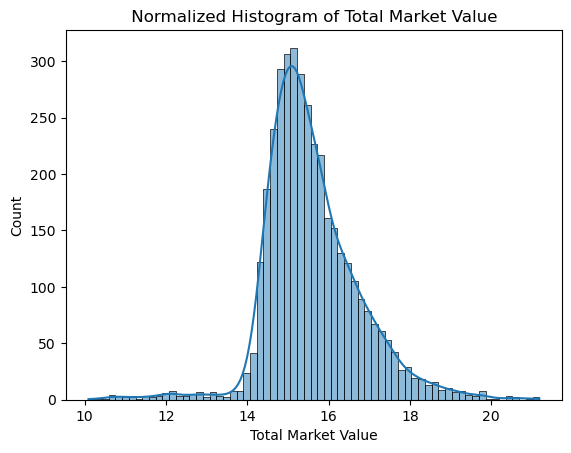

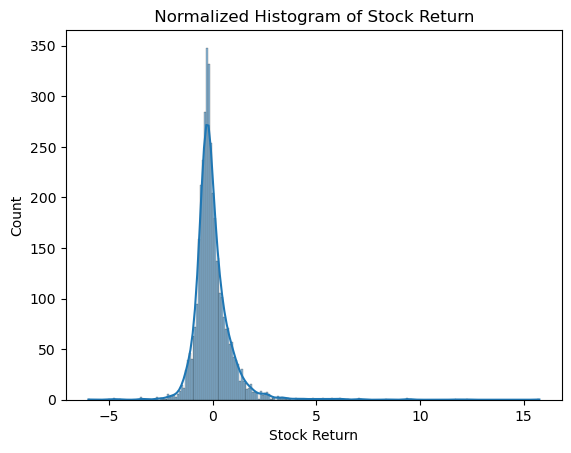

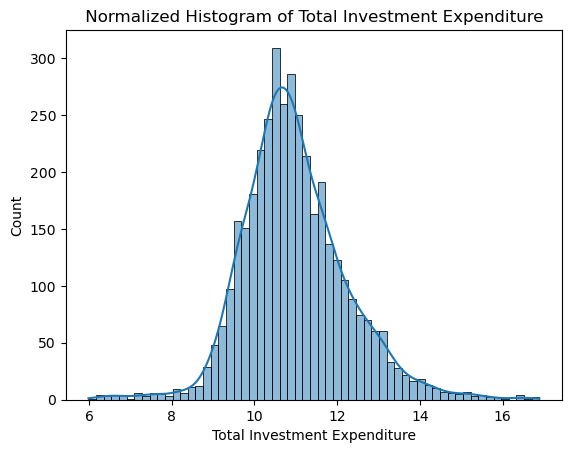

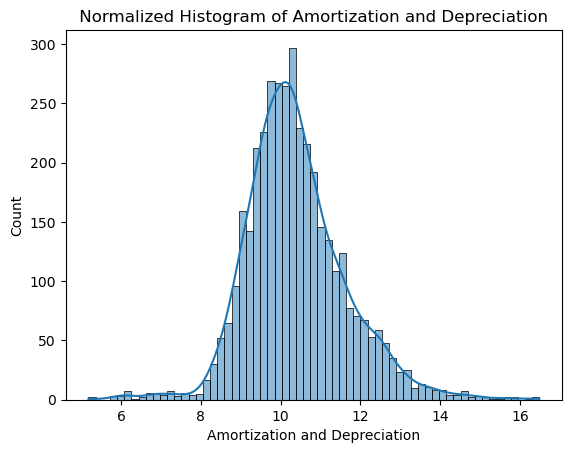

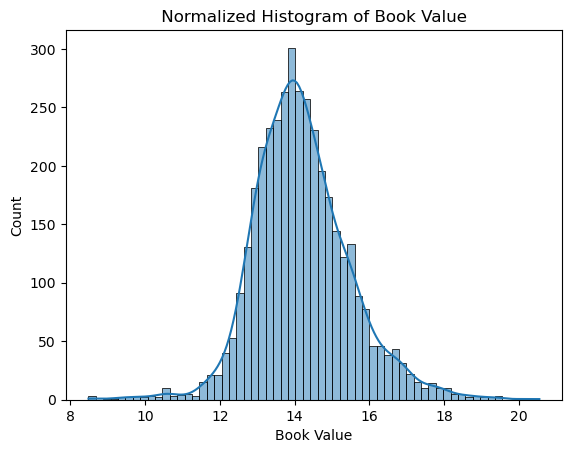

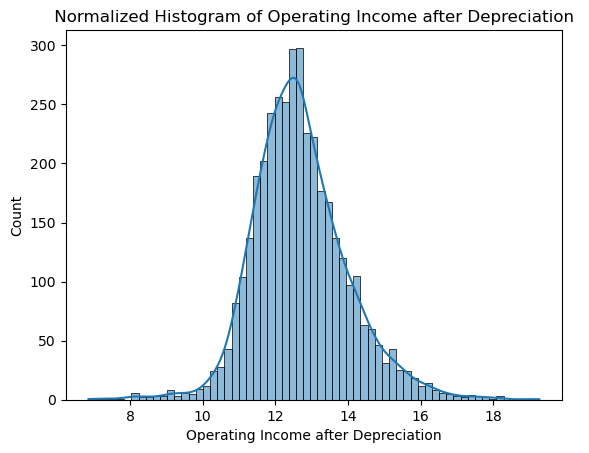

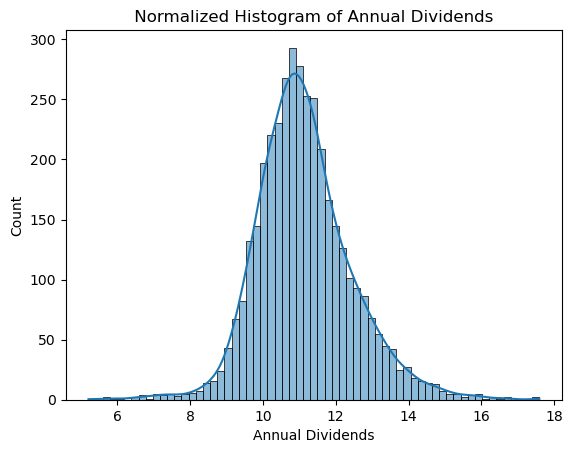

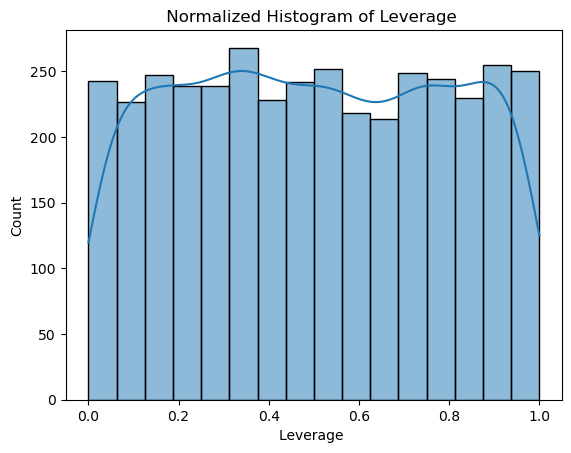

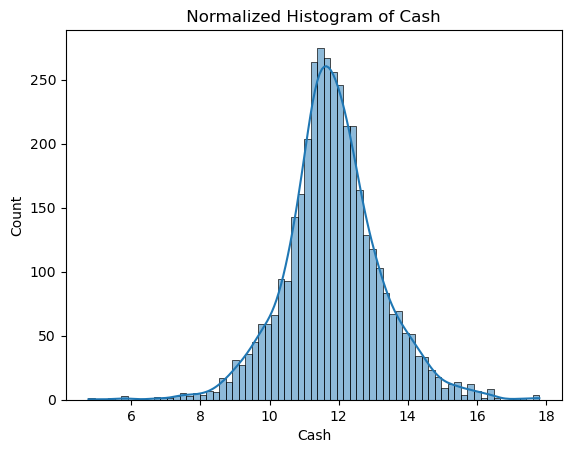

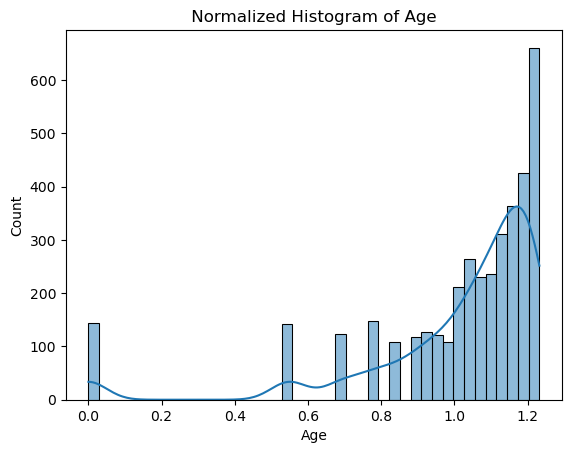

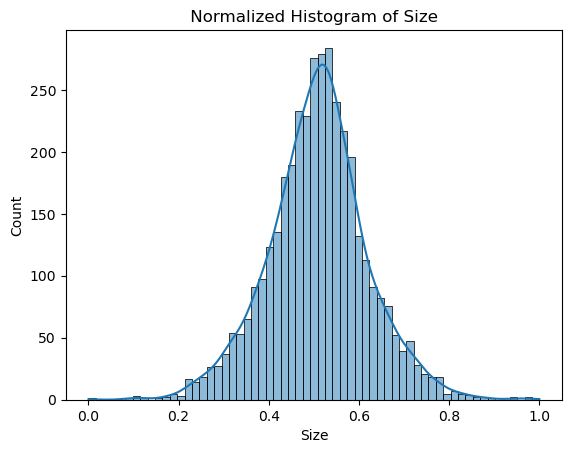

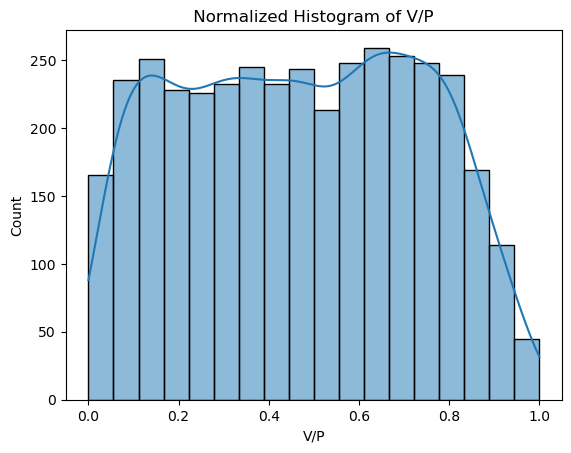

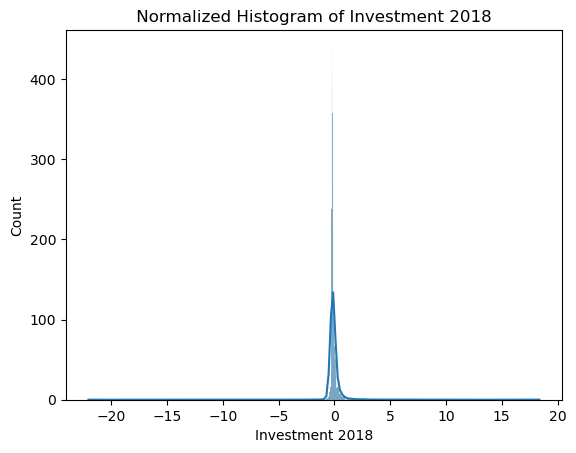

In [629]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in df.columns:
    sns.histplot(df[feature], kde = True)
    plt.title(f' Normalized Histogram of {feature} ' )
    plt.show()
    

In [631]:
numeric_columns = df.select_dtypes(include =[ np.number]).columns
for column in numeric_columns:
    skewness =  df[column].skew()
    print(f" Columns: {column}, Skewness : {skewness} ")

 Columns: Stock Code, Skewness : -0.007983630992419008 
 Columns: Market Value of Equity, Skewness : 0.5382300690321298 
 Columns: Total Market Value, Skewness : 0.45926409499214743 
 Columns: Stock Return, Skewness : 3.965441628287212 
 Columns: Total Investment Expenditure, Skewness : 0.4840025113495881 
 Columns: Amortization and Depreciation, Skewness : 0.5234051515327822 
 Columns: Book Value, Skewness : 0.430479123370767 
 Columns: Operating Income after Depreciation, Skewness : 0.4394524184550775 
 Columns: Annual Dividends, Skewness : 0.4431769109618714 
 Columns: Leverage , Skewness : 0.011917307876520292 
 Columns: Cash, Skewness : 0.10225761556846338 
 Columns: Age, Skewness : -2.3466651859895347 
 Columns: Size, Skewness : 0.013732067826787485 
 Columns: V/P, Skewness : 0.008372917958415865 
 Columns: Investment 2018, Skewness : 5.981361295266389 


In [637]:
pt = PowerTransformer(method='yeo-johnson')
df['Stock Return'] = pt.fit_transform(df[['Stock Return']])
df['Age'] = pt.fit_transform(df[['Age']])

from scipy.stats import boxcox
df['Cash'], lambda_value = boxcox(df['Cash'])



from sklearn.preprocessing import QuantileTransformer
transformer = QuantileTransformer(output_distribution='normal')
df['Investment 2018'] = transformer.fit_transform(df[['Investment 2018']])


In [639]:
numeric_columns = df.select_dtypes(include =[ np.number]).columns
for column in numeric_columns:
    skewness =  df[column].skew()
    print(f" Columns: {column}, Skewness : {skewness} ")

 Columns: Stock Code, Skewness : -0.007983630992419008 
 Columns: Market Value of Equity, Skewness : 0.5382300690321298 
 Columns: Total Market Value, Skewness : 0.45926409499214743 
 Columns: Stock Return, Skewness : -0.2539877769103206 
 Columns: Total Investment Expenditure, Skewness : 0.4840025113495881 
 Columns: Amortization and Depreciation, Skewness : 0.5234051515327822 
 Columns: Book Value, Skewness : 0.430479123370767 
 Columns: Operating Income after Depreciation, Skewness : 0.4394524184550775 
 Columns: Annual Dividends, Skewness : 0.4431769109618714 
 Columns: Leverage , Skewness : 0.011917307876520292 
 Columns: Cash, Skewness : 0.07020975075397573 
 Columns: Age, Skewness : -0.0970033554270087 
 Columns: Size, Skewness : 0.013732067826787485 
 Columns: V/P, Skewness : 0.008372917958415865 
 Columns: Investment 2018, Skewness : 0.0010993049841181062 


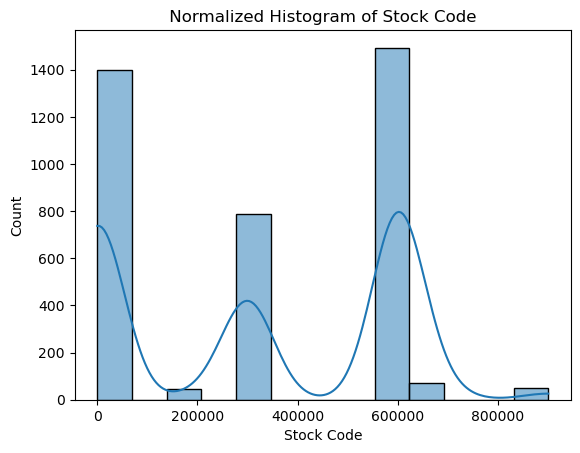

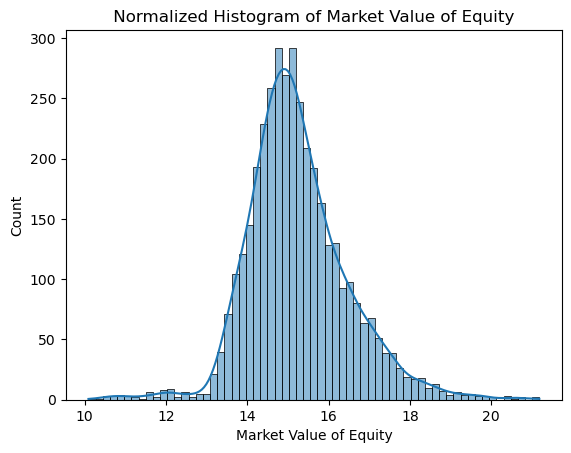

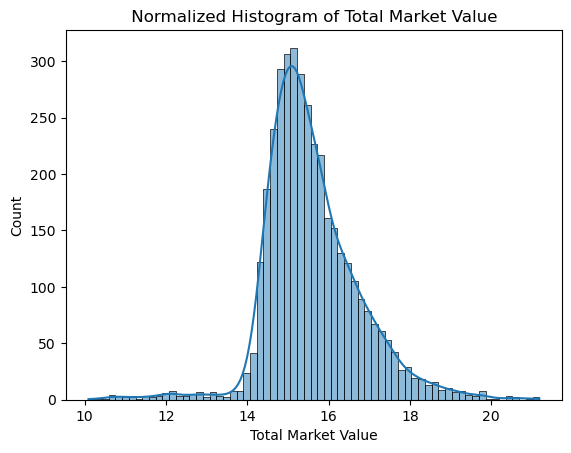

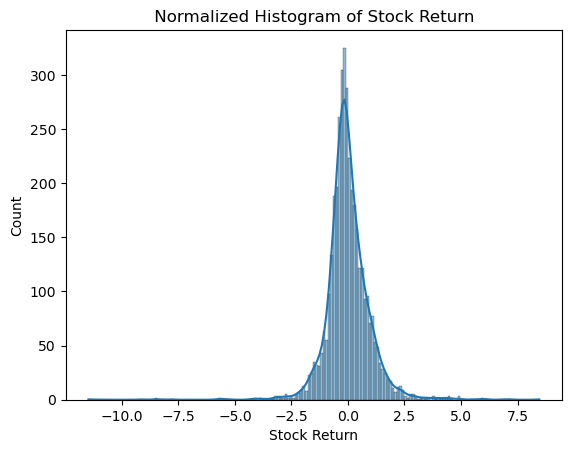

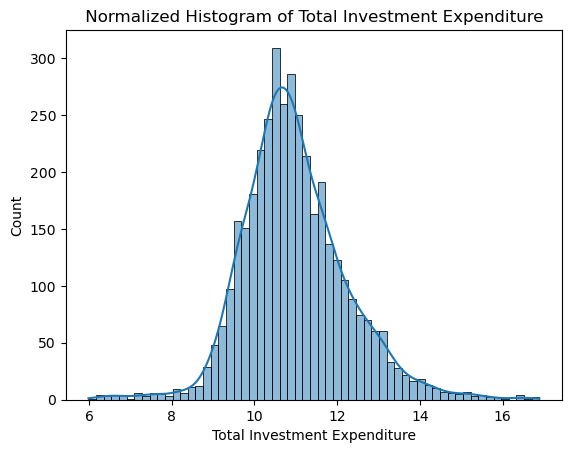

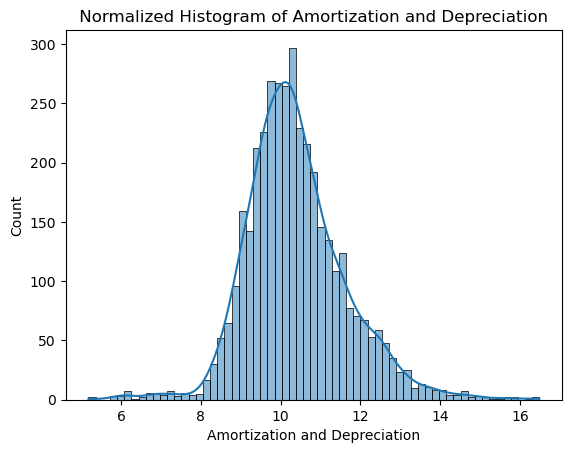

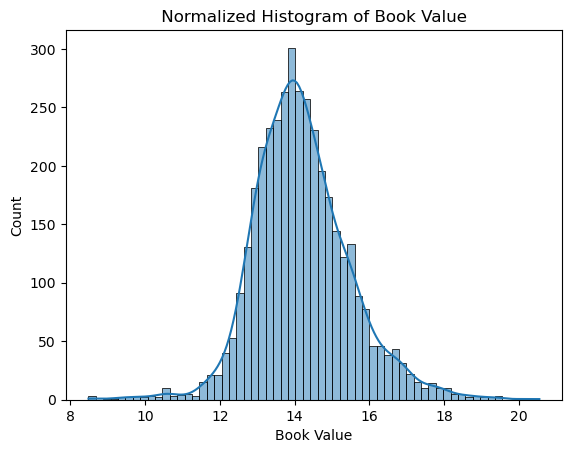

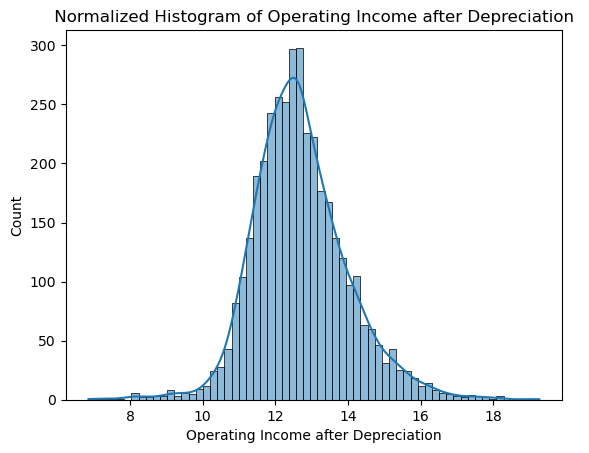

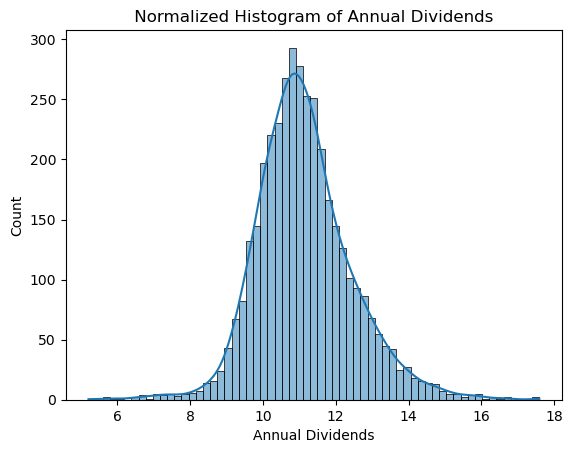

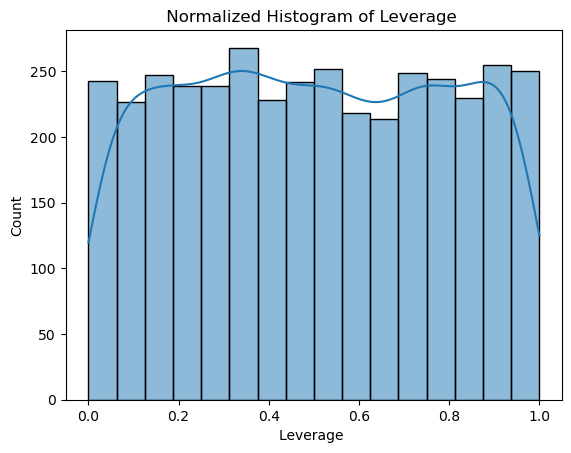

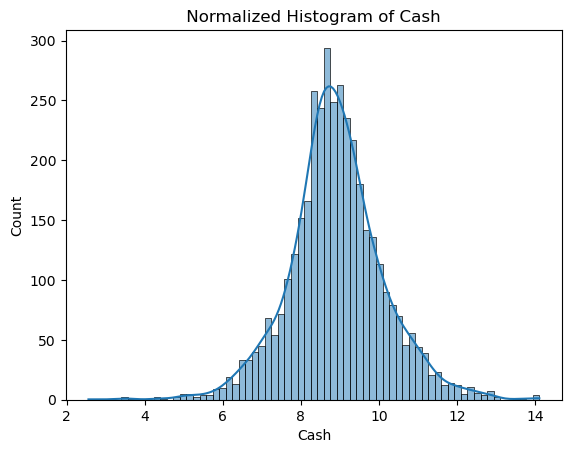

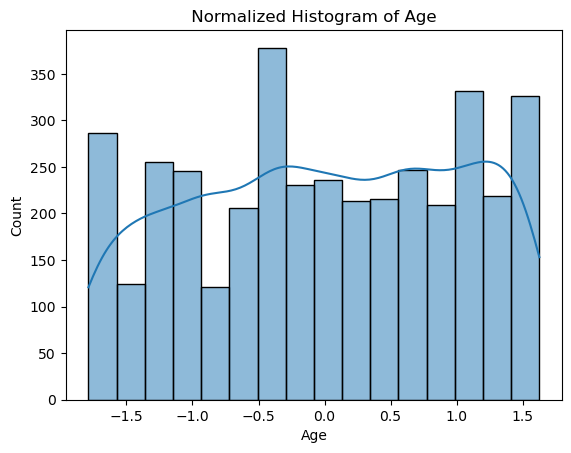

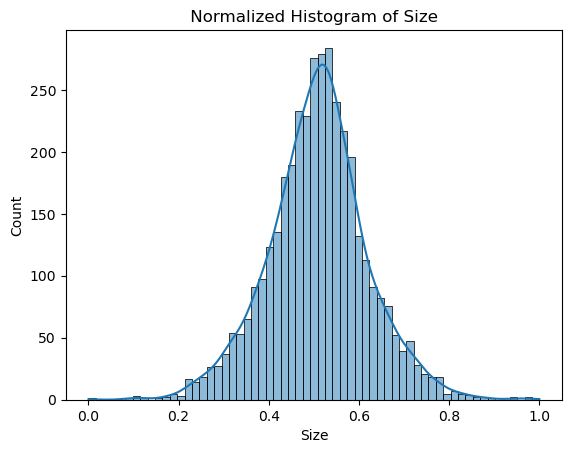

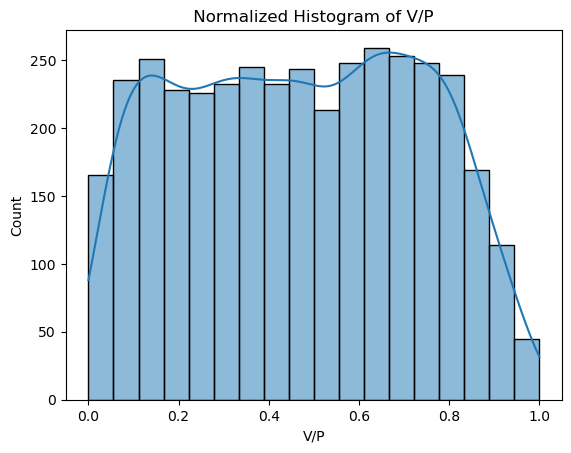

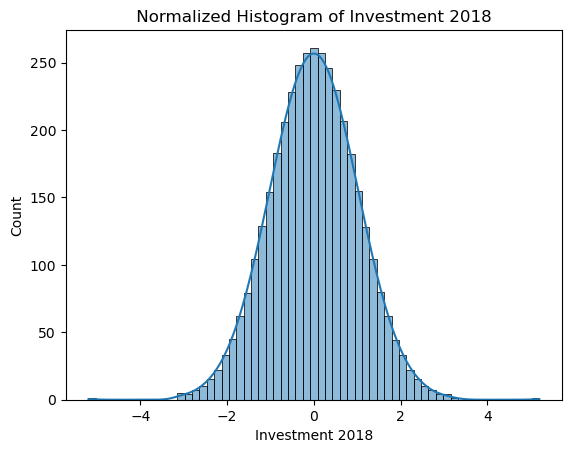

In [641]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in df.columns:
    sns.histplot(df[feature], kde = True)
    plt.title(f' Normalized Histogram of {feature} ' )
    plt.show()

Question 2 B

What methods I used and why for each Distribution plot

Firstly, i started off by plotting a hisogram for each column in the dataset. This helped me immensly as i was able to look at the data for each column and understand the shape/ skewness for each feature in the data, thus giving me an idea of how to normalise the columns based off their data types and shape. 

For each distribution plot, i chose to use a histogram as i feel this graph has many benefits. For example, the histograms, provided a clear, simplistic visualisation of the data, allowing me to see how the data was spread out and the frequency of the data within the bins. Secondly, the histograms were straightforward in enabling me to identify skewness within the data. I was easily able to spot if the data was right skewed meaning positive or left skewed meaning negative. Furthermore, through looking at the histograms, i was able to spot outliers ( data that stood out) within the graphs. Moreover, as all the graphs were histograms, this made it easier for comparison between graphs, especially when the data is affected by diferent transformations/ normalization methods. Therefore this enabled me to gain a beter overall understanding of the data and the affect of transformations.

Finally, through observing the different histograms and shape within each graph, i chose to apply a normalization method i thought would best suit that column/ feature based off the characteristics of their graph :

Firstly, I chose to apply the min/max normalization to 3 distribution plots / columns. The "Size", "Leverage" and "V/P" graphs all stood out as having a uniform distribution with no significant outliers. These characteristics are best suited a min/max normalization because the min/max method scales the data between 0 and 1, therefore meaning a more unified distribution helps to maintain this spread as well as making the data more predictable and consistent

Secondly, I had initially decided to apply the Power transformation ( Yeo-Johnson) to the Investment 2018 column as this graph showed both positive and negative values, which this normalization method is able to handle

Thirdly, most of the distribution plots represented a right skew , with no negative values.  I therefore chose to apply the Logarithmic normalization method to the majority of the columns, as they did not contain a 0 or negative values. This normalization method was good for reducing the skewness of the data and handling outliers. 

Finally, i chose to use a z-score normalization for the ' Stock Return' column as this method can handle negative values and is suited to graphs which appear more normal. 

I then changed the normalization method for certain features, after doing a skewness test and finding out that the skewness for those graphs were too large. 





In [648]:
# Removing Outliers using the Inter Quartile Range

# Calculating the IQR

for feature in df.columns:
    
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

# Defining the Upper and Lower bounds 

    Lower_bound = Q1 - ( IQR * 1.5)
    Upper_bound = Q3 + ( IQR * 1.5) 
                        
# Filtering out the outliers

    df = df[(df[feature] >= Lower_bound) & (df[feature] <= Upper_bound)]

df.to_csv('Cleaned_dataset.csv')


In [650]:
numeric_columns = df.select_dtypes(include =[ np.number]).columns
for column in numeric_columns:
    skewness =  df[column].skew()
    print(f" Columns: {column}, Skewness : {skewness} ")

 Columns: Stock Code, Skewness : -0.00880389721522272 
 Columns: Market Value of Equity, Skewness : 0.36041338214918284 
 Columns: Total Market Value, Skewness : 0.5139636387112511 
 Columns: Stock Return, Skewness : 0.1638157536177392 
 Columns: Total Investment Expenditure, Skewness : 0.25651883288937827 
 Columns: Amortization and Depreciation, Skewness : 0.32807836693610476 
 Columns: Book Value, Skewness : 0.2207045665538107 
 Columns: Operating Income after Depreciation, Skewness : 0.2138738396043664 
 Columns: Annual Dividends, Skewness : 0.20775461254102257 
 Columns: Leverage , Skewness : 0.02293022339370779 
 Columns: Cash, Skewness : -0.014618212067210277 
 Columns: Age, Skewness : -0.09944794515450488 
 Columns: Size, Skewness : -0.03720158780128239 
 Columns: V/P, Skewness : 0.033098446593554015 
 Columns: Investment 2018, Skewness : -0.18139189788292523 


In [654]:
# Question 3 A
# Descriptive Statistic summary
df.describe()

,Stock Code,Market Value of Equity,Total Market Value,Stock Return,Total Investment Expenditure,Amortization and Depreciation,Book Value,Operating Income after Depreciation,Annual Dividends,Leverage,Cash,Age,Size,V/P,Investment 2018
count,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000
mean,309075.357054,15.134576,15.484142,-0.035146,10.871302,10.275264,14.084655,12.569131,11.013546,0.498565,8.819778,-0.000319,0.506676,0.463958,-0.048900
std,267363.152089,0.928090,0.819004,0.666802,0.976150,0.952931,0.995608,1.006857,1.017046,0.291346,0.938963,0.992934,0.094778,0.261996,0.865097
min,4.000000,12.953424,13.150722,-1.770147,8.181105,8.009725,11.341899,9.891385,8.365695,0.000000,6.436268,-1.787598,0.258200,0.000000,-2.483646
25%,2487.750000,14.490045,14.864002,-0.437568,10.198154,9.602430,13.358150,11.854284,10.285470,0.244918,8.252354,-0.827010,0.446905,0.237404,-0.641285
50%,300427.500000,15.056639,15.345947,-0.096510,10.802790,10.202280,14.024152,12.520095,10.960461,0.494266,8.797152,0.003379,0.509436,0.462518,-0.026351
75%,600692.250000,15.718331,15.996711,0.373973,11.525399,10.881824,14.745543,13.226155,11.659914,0.752945,9.424374,0.893401,0.567572,0.685210,0.581769
max,900948.000000,17.839535,17.925272,1.739366,13.603767,12.883424,16.912245,15.353082,13.753594,1.000000,11.243292,1.625837,0.756942,1.000000,2.035676


In [ ]:
# Section 4

Investment2019 =  w1 ∗ V/P + w2 ∗ Leverage + w3 ∗ Cash + w4 ∗ Age + w5 ∗ Size 
+ w6 ∗ Stock Return + w7 ∗ Investment2018 + 𝜷 